In [29]:
# 1. Import Libraries:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.Load the 'taxis' dataset:

In [30]:
df = sns.load_dataset("taxis") 
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


### 2.Handling Missing Values:

* Check for missing values in the dataset and identify columns with missing data:

In [31]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

* Impute missing values using appropriate strategies in Categorical (Text) Columns with the Mode:

In [32]:
for col in ["payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]:
    df[col] = df[col].fillna(df[col].mode()[0])

* Fill Missing Values in Numerical Columns with the Median:

In [33]:
for col in ["passengers", "distance", "fare", "tip", "tolls", "total"]:
    df[col] = df[col].fillna(df[col].median())

* Remove Rows Where Critical Data Is Missing:

In [34]:
df = df.dropna(subset=["pickup", "dropoff"])

* Verify missing values:

In [35]:
print("Remaining Missing Values:")
print(df.isnull().sum().sum())


print("Cleaned Dataset Shape:", df.shape)

Remaining Missing Values:
0
Cleaned Dataset Shape: (6433, 14)


### 3.Visualizations using Matplotlib/Pandas Plot: 

##### 3.1 ★ Line Chart - Fare over time:

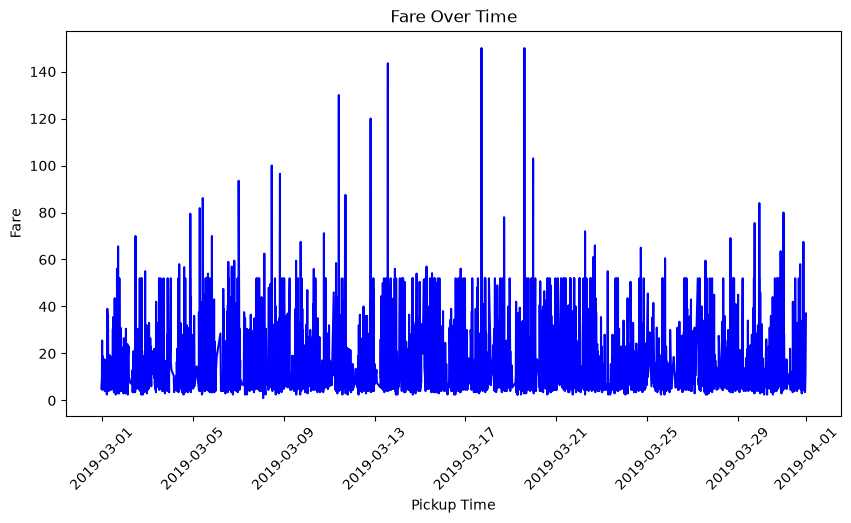

In [57]:
# 3.1★ Line Chart:
# Visualize fare over time using pickup timestamp on the X-axis and fare on the Y-axis.
# Convert pickup column into datetime first

df["pickup"] = pd.to_datetime(df["pickup"]) 

# Sort data by pickup time:

df_sorted = df.sort_values('pickup')

# Create line chart:
plt.figure(figsize=(10, 5))
plt.plot(df_sorted["pickup"], df_sorted["fare"], color="blue")
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.show()

##### 3.2 ★ Bar Chart - Total fare per pickup borough :

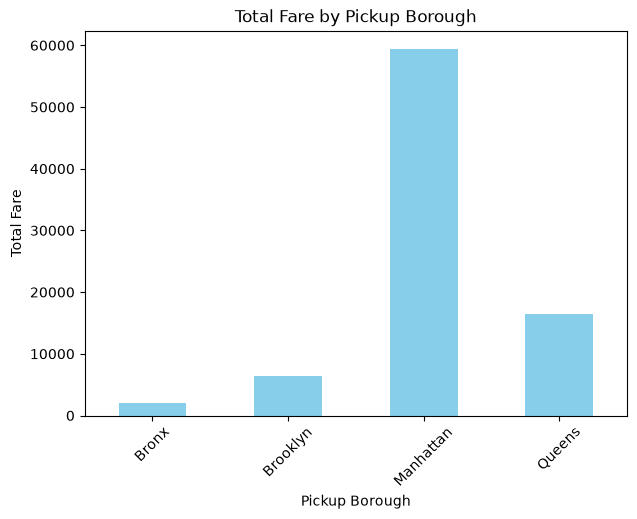

In [58]:
# Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group:

df.groupby("pickup_borough")["fare"].sum().plot(kind="bar", color="skyblue", figsize=(7, 5))
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.show()

##### 3.3 ★ Pie Chart - Trips by payment method :

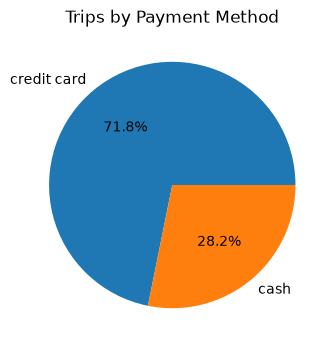

In [56]:
# Plot a pie chart showing the distribution of trips based on the payment method:

df["payment"].value_counts().plot(kind="pie", autopct="%1.1f%%", figsize=(6, 4))
plt.title("Trips by Payment Method")
plt.ylabel("")
plt.show()

##### 3.4 ★ Histogram - Distribution of distance:

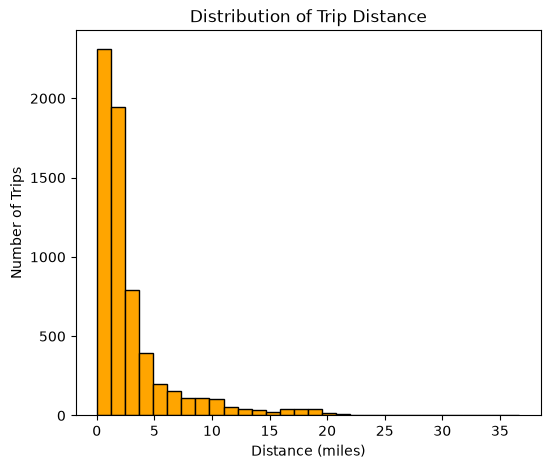

In [49]:
# Create a histogram to visualize the distribution of distance.Customize the number of bins for better granularity and ensure the plot is easy to interpret:

plt.figure(figsize=(6, 5))
plt.hist(df["distance"], bins=30, color="orange", edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")

plt.show()

##### 3.5 ★ Box Plot - Tip by pickup borough:

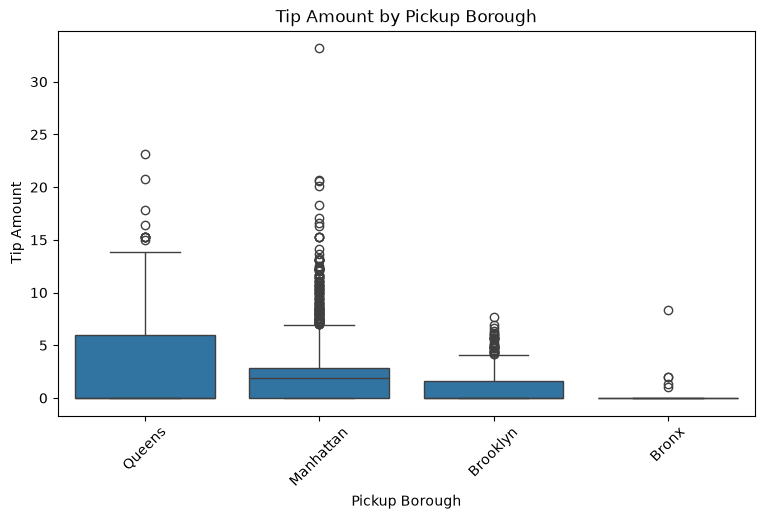

In [66]:
# Visualize the distribution of tip amounts for each pickup_borough. Use pickup_borough as the categorical axis and tip as the numeric axis:

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='pickup_borough',
    y='tip'
)

plt.title('Tip Amount by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')

plt.xticks(rotation=45)
plt.show()

### 4.Visualizations using Seaborn:

##### 4.1 ★ Count Plot -  

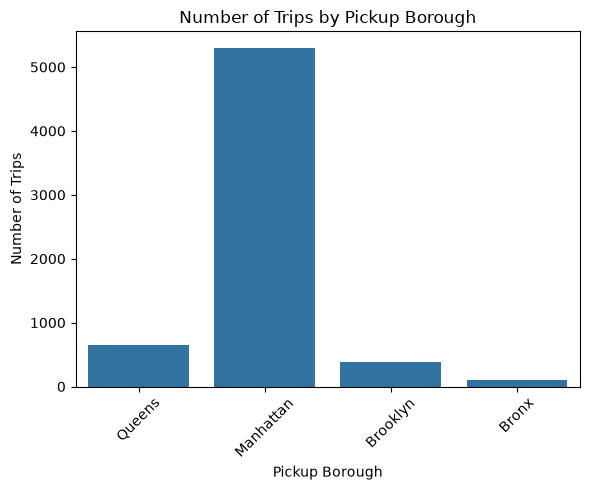

In [62]:
# Visualize the number of trips in each pickup_borough. The x-axis represent the boroughs, and the y-axis should show the count of trips:

plt.figure(figsize=(6, 5))
sns.countplot(x="pickup_borough", data=df)
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### 4.2 ★ Scatter Plot - Distance vs fare, colored by borough:

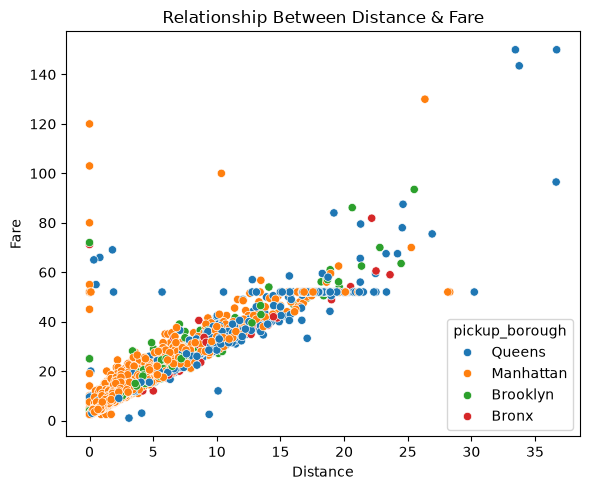

In [70]:
# Show the relationship between distance and fare, Use distance on the x-axis and fare on the y-axis to visualize any correlation:

plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=df,
    x="distance", 
    y="fare", 
    hue="pickup_borough", 
)

plt.title("Relationship Between Distance & Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")

plt.tight_layout()
plt.show()



##### 4.3 ★ Heatmap - Correlation:

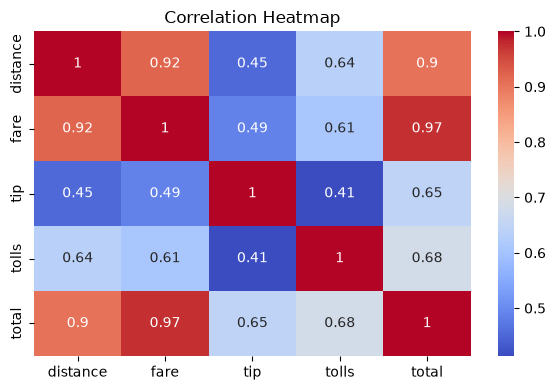

In [73]:
# Visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total:

# Calculate correlation:

corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


##### 4.4 ★ Pair Plot  - Pairwise relationships:

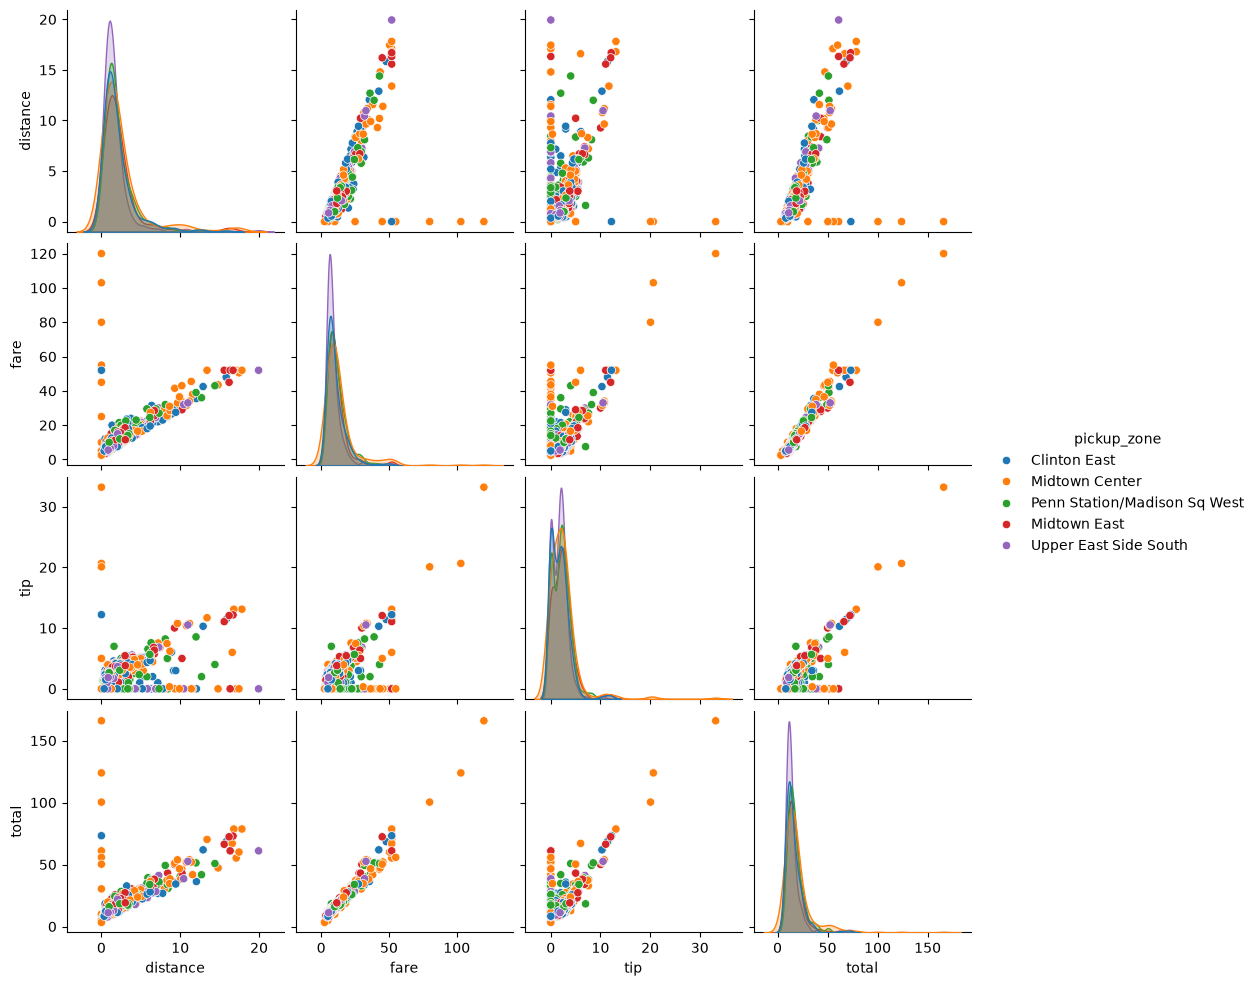

In [75]:
# Visualize pairwise relationships between distance, fare, tip and total. Colour observations according to pickup zone:

# Select top 5 pickup zones:

top_zones = df["pickup_zone"].value_counts().head(5).index

df_top = df[df["pickup_zone"].isin(top_zones)]
sns.pairplot(df_top[["distance", "fare", "tip", "total", "pickup_zone"]], hue="pickup_zone")
plt.show()


##### 4.5 ★ Violin Plot - Fare by payment method:

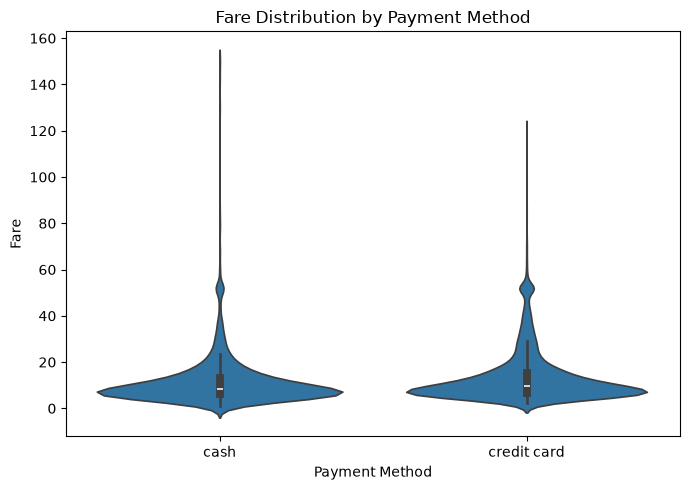

In [80]:
# Show fare distribution for each payment method. Use the payment method as the categorical axis and fare as the numeric axis:

plt.figure(figsize=(7, 5))
sns.violinplot(x="payment", y="fare", data=df)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")

plt.tight_layout()
plt.show()